# 1 Problem
Recover two intensity-weighted hydrodynamic radius populations from author carbonic-anhydrase DLS observations. The inverse Laplace problem needs an explicit prior. We evaluate a continuous conditional nonnegative Tikhonov–Phillips target, without asserting independent molecular truth.

In [1]:
from pathlib import Path
import sys,time,json,importlib.util,numpy as np
root=Path.cwd()
if not (root/"src").exists():root=root.parent
sys.path.insert(0,str(root))
from src.main import run
from src.solvers import compare_lcurve
from src.visualization import comparison
from src.physics_model import objective,kernel
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

# 2 Data
Two native carbonic-anhydrase measurements share817nm laser,150degree detection,293K solvent, viscosity8.9e-4Pa s and refractive index1.33. The first raw lag remains in the public observations but is excluded by the source analysis convention. Every other373 lag channel receives a modeled intensity prediction.

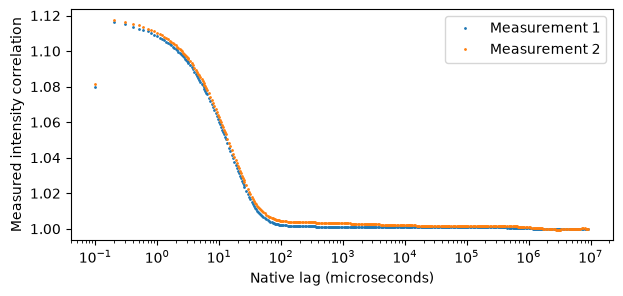

In [2]:
raw=np.load(root/"data/raw_data.npz")
fig,ax=plt.subplots(figsize=(7,3));
for j in range(2):ax.semilogx(raw["lag_us"][0],raw["correlation"][0,j],".",ms=2,label=f"Measurement {j+1}")
ax.set(xlabel="Native lag (microseconds)",ylabel="Measured intensity correlation");ax.legend();plt.show()

# 3 Physics
For hydrodynamic radius R, the Stokes–Einstein diffusion coefficient is D=kB*T/(6*pi*eta*R). Scattered field correlation is a Laplace mixture over diffusion rates:

$$
q=4\pi n\sin(\theta/2)/\lambda,\quad s_j=1/(D_jq^2),\quad h(t)=\sum_j p_j e^{-t/s_j},\quad G(t)=1+\beta h(t)^2.
$$

p is intensity bin mass without bin-width normalization. Coherence beta is estimated by the source early-lag log-quadratic intercept protocol. Negative G-1 at late lags is correlation noise; the source field-correlation objective uses the prefix before its first invalid square root. Both the selected data domain and full prediction domain are shown explicitly.

# 4 Method
The fixed alpha0.1 benchmark solves a nonnegative augmented least-squares problem with explicit Laplace kernel, index second differences and1000-weight mass/endpoint soft constraints. Separately, the entire original80-weight L-curve comparison is actively recomputed and uses the same triangle corner definition. These methods use the same measured data but different regularization conditions.

In [3]:
start=time.perf_counter()
t,g,r,s,beta,field,valid,p,pred,residual,penalty=run(root)
alphas,res,pen,selected,adaptive,adaptive_pred=compare_lcurve(t,g,s,beta,field,valid)
runtime=time.perf_counter()-start
up=np.load(root/"test/fixtures/upstream.npz")
up_lcurve=np.load(root/"notebooks/reference_outputs/upstream_lcurve.npz")
print("Active reconstruction and complete L-curve seconds:",runtime)
print("Valid field-correlation prefix lengths:",valid)
table="|Measurement|Coherence beta|Mass sum|Fixed-alpha mode radius (nm)|L-curve alpha|\n|---|---|---|---|---|\n"
for j in range(2):table+=f"|{j+1}|{beta[j]:.8g}|{p[j].sum():.8g}|{r[p[j].argmax()]:.8g}|{selected[j]:.8g}|\n"
display(Markdown(table))

Active reconstruction and complete L-curve seconds: 0.4477678999537602
Valid field-correlation prefix lengths: [329 336]


|Measurement|Coherence beta|Mass sum|Fixed-alpha mode radius (nm)|L-curve alpha|
|---|---|---|---|---|
|1|0.11720535|0.99999598|2.5461324|0.2|
|2|0.11871368|0.99999215|2.3467951|0.38073079|


# 5 Results
The panel preserves measured correlations, both measured groups, fixed-prior populations, independent upstream populations, the fresh adaptive-prior comparison, the complete L curve and full intensity residuals. The table below compares forward-fit error on the common measured intensity scale; changing alpha changes the regularized target, so objective values at different weights are not mislabeled as the same metric.

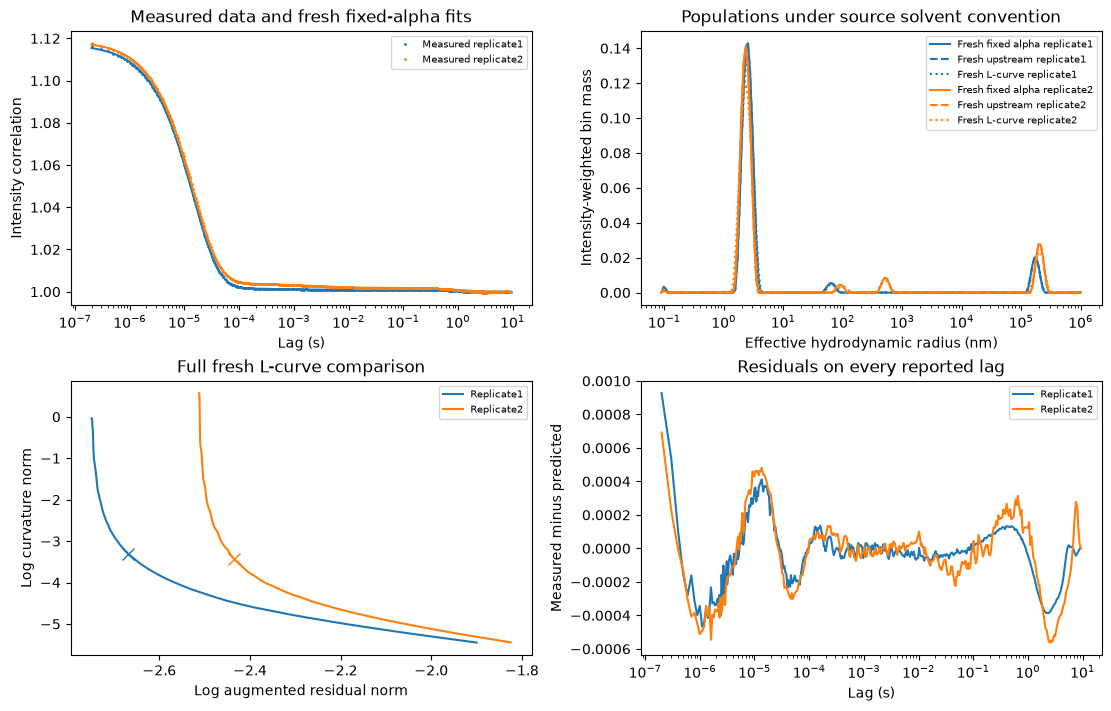

|Measurement|Fresh fixed-alpha G2 SSE|Fresh L-curve G2 SSE|Upstream fixed-alpha G2 SSE|
|---|---|---|---|
|1|1.08331989e-05|1.21529121e-05|1.08331989e-05|
|2|1.80802768e-05|2.15589928e-05|1.80802768e-05|


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "objective_0": 0.004641961921034329,
    "forward_relative_l2_0": 0.0,
    "objective_1": 0.007263545453099569,
    "forward_relative_l2_1": 0.0
  },
  "thresholds": {
    "objective_0": {
      "comparison": "<=",
      "boundary": 0.004642426117226444
    },
    "forward_relative_l2_0": {
      "comparison": "<=",
      "boundary": 1e-10
    },
    "objective_1": {
      "comparison": "<=",
      "boundary": 0.007264271807644887
    },
    "forward_relative_l2_1": {
      "comparison": "<=",
      "boundary": 1e-10
    }
  },
  "errors": []
}


In [4]:
fig=comparison(t,g,r,p,pred,up["output_spectrum"],alphas,res,pen,selected,adaptive)
plt.show()
rows="|Measurement|Fresh fixed-alpha G2 SSE|Fresh L-curve G2 SSE|Upstream fixed-alpha G2 SSE|\n|---|---|---|---|\n"
for j in range(2):rows+=f"|{j+1}|{np.sum((g[:,j]-pred[:,j])**2):.9g}|{np.sum((g[:,j]-adaptive_pred[:,j])**2):.9g}|{np.sum((g[:,j]-up['output_prediction'][:,j])**2):.9g}|\n"
display(Markdown(rows))
spec=importlib.util.spec_from_file_location("judge",root/"evaluation/judge.py");judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(root/"output/reconstruction.npz");print(json.dumps(report,indent=2));assert exit_code==0

# 6 Conclusion
The active local inverse reaches the same declared convex objective as the independently executed original method. Both measured populations and the adaptive-regularization comparison are preserved. Fine population detail depends on the prior, and inferred intensity-weighted hydrodynamic radius is not a molecular number distribution. The broad radius domain and complete residuals remain visible, and no independently known radius truth is claimed. Effective radius coordinates are conditional on the declared293K and8.9e-4Pa s solvent conventions; independent solvent calibration was not supplied.